# EEG and EMG in Spyglass: DANDI:001888 (Gonzalez-Sulser lab)

Each file of [DANDI:001888](https://dandiarchive.org/dandiset/001888) holds one rat's chronic wireless recording:
14 EEG channels from skull screws over the cortex and 2 EMG channels from the neck muscle, sampled at about
250 Hz for 3 to 4 days. This notebook reads the recordings back through a Spyglass database.

The EEG/EMG tables come from [LorenFrankLab/spyglass#1638](https://github.com/LorenFrankLab/spyglass/pull/1638),
which is not merged yet. Until it is, the environment installs them from the `gonzalez-sulser-example-v1` tag of
the CatalystNeuro Spyglass fork:

- `ElectrodeGroup` and `Electrode` (Spyglass's standard electrode tables) hold the two arrays, `EEGArray` and
  `EMGArray`, and their 16 electrodes.
- `ImportedEEG` has one row per `ElectricalSeries` in the file's acquisition whose electrodes belong to an EEG or
  EMG group: `EEGElectricalSeries` and `EMGElectricalSeries`. Its `.Electrode` part maps each column of the series
  to its electrode.

`ImportedEEG` stores the object id of each series and its valid times, not the samples: the trace stays in the NWB
file and `nwb_object()` opens it. No filtering is applied at ingestion.

**Running it:** this notebook runs in the `spyglass-gonzalez-sulser-lab-env` conda env inside WSL2, created with `../bootstrap_wsl.sh`. The database is the `spyglass-db` Docker container on port 3306; see `../docker-compose.yml`, `../dj_local_conf.json` and the [Spyglass ingestion docs](../../docs/spyglass_ingestion.md). Ingest the files with `../insert_full_session.py` first.

In [1]:
from pathlib import Path

import datajoint as dj

# Load the connection config BEFORE importing spyglass: spyglass declares its schemas
# at import time and would otherwise connect with default settings (including TLS,
# which the local Docker MySQL doesn't use).
dj.config.load(str(Path("..") / "dj_local_conf.json"))
dj.conn(use_tls=False)

[2026-11-19 11:32:19,311][INFO]: DataJoint is configured from /mnt/c/Users/amtra/CatalystNeuro/gonzalez-sulser-lab-to-nwb/src/gonzalez_sulser_lab_to_nwb/hristova_2025/spyglass/dj_local_conf.json


[2026-11-19 11:32:19,321][INFO]: DataJoint 0.14.10 connected to root@127.0.0.1:3306


DataJoint connection (connected) root@127.0.0.1:3306

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pynwb import NWBHDF5IO

from spyglass.common import (
    BrainRegion,
    Electrode,
    ElectrodeGroup,
    ImportedEEG,
    IntervalList,
    Nwbfile,
    Session,
    Subject,
)
from spyglass.settings import raw_dir

GENOTYPE_LABELS = {"LE-Grin2bem1Mcwi": "Het", "WT": "WT"}

sessions = (
    pd.DataFrame(
        (Session * Subject).fetch(
            "nwb_file_name", "subject_id", "sex", "genotype", "session_start_time", as_dict=True
        )
    )
    .assign(genotype=lambda df: df["genotype"].map(GENOTYPE_LABELS))
    .sort_values("subject_id")
    .reset_index(drop=True)
)
print(f"{len(sessions)} sessions")
sessions

24 sessions


,nwb_file_name,subject_id,session_start_time,genotype,sex
0,sub-GRIN2B-129_ses-2021-03-26_ecephys_.nwb,GRIN2B-129,2021-03-26 10:56:00,Het,M
1,sub-GRIN2B-130_ses-2021-03-26_ecephys_.nwb,GRIN2B-130,2021-03-26 10:56:00,Het,M
2,sub-GRIN2B-131_ses-2021-03-26_ecephys_.nwb,GRIN2B-131,2021-03-26 10:56:00,Het,M
3,sub-GRIN2B-132_ses-2021-03-26_ecephys_.nwb,GRIN2B-132,2021-03-26 10:56:00,WT,M
4,sub-GRIN2B-137_ses-2021-03-31_ecephys_.nwb,GRIN2B-137,2021-03-31 10:22:00,Het,F
5,sub-GRIN2B-138_ses-2021-03-31_ecephys_.nwb,GRIN2B-138,2021-03-31 10:22:00,Het,F
6,sub-GRIN2B-139_ses-2021-03-31_ecephys_.nwb,GRIN2B-139,2021-03-31 10:22:00,Het,F
7,sub-GRIN2B-140_ses-2021-03-31_ecephys_.nwb,GRIN2B-140,2021-03-31 10:22:00,WT,F
8,sub-GRIN2B-227_ses-2021-07-28_ecephys_.nwb,GRIN2B-227,2021-07-28 10:08:00,Het,M
9,sub-GRIN2B-228_ses-2021-07-28_ecephys_.nwb,GRIN2B-228,2021-07-28 10:08:00,Het,M


## Checks

Every file should have the two electrode groups, 16 electrodes (14 EEG, 2 EMG), the two series in `ImportedEEG`
with one `.Electrode` row per channel, and the two baseline windows of the epochs table in `IntervalList`.

In [3]:
EXPECTED_SERIES = {"EEGElectricalSeries": 14, "EMGElectricalSeries": 2}

for name in sessions["nwb_file_name"]:
    key = {"nwb_file_name": name}
    groups = set((ElectrodeGroup & key).fetch("electrode_group_name"))
    assert groups == {"EEGArray", "EMGArray"}, f"{name}: groups {groups}"
    assert len(Electrode & key) == 16, f"{name}: {len(Electrode & key)} electrodes"
    series = dict(zip(*(ImportedEEG & key).fetch("name", "eeg_object_id")))
    assert set(series) == set(EXPECTED_SERIES), f"{name}: series {set(series)}"
    for series_name, n_channels in EXPECTED_SERIES.items():
        n_rows = len(ImportedEEG.Electrode & key & {"eeg_object_id": series[series_name]})
        assert n_rows == n_channels, f"{name}: {series_name} has {n_rows} channels"
    intervals = set((IntervalList & key).fetch("interval_list_name"))
    assert {"baseline_window_1", "baseline_window_2"} <= intervals, f"{name}: intervals {intervals}"

print(f"All checks passed for {len(sessions)} session(s).")

All checks passed for 24 session(s).


## 1. Electrodes

`Electrode` holds each electrode of a session with its group and its region in `BrainRegion`. Spyglass takes the
region from the electrode group, so every EEG electrode is in `cerebral cortex` and every EMG electrode in
`trapezius muscle`. The position of each screw (`x` anterior-posterior and `z` medial-lateral, in µm from bregma)
is kept.

The NWB file's electrodes table also has each electrode's channel name and its cortical area, which Spyglass's
`Electrode` has no column for. They are read from the file below and joined on the electrode id. The
[HED and HERD notebook](spyglass_hed_herd_tutorial.ipynb) shows the ontology terms linked to these areas.

In [4]:
example = sessions[sessions["subject_id"] == "GRIN2B-424"].iloc[0]
example_key = {"nwb_file_name": example["nwb_file_name"]}

electrodes = (
    (Electrode * BrainRegion & example_key)
    .fetch(format="frame")
    .reset_index()[["electrode_group_name", "electrode_id", "region_name", "x", "z"]]
)

# Channel names and cortical areas, from the NWB file's electrodes table
nwbfile = (Nwbfile & example_key).fetch_nwb()[0]
file_electrodes = nwbfile.electrodes.to_dataframe()[["channel_name", "location", "hemisphere"]]
(Nwbfile & example_key).close_nwb()

electrodes = electrodes.merge(file_electrodes, left_on="electrode_id", right_index=True)
electrodes.sort_values("electrode_id").reset_index(drop=True)

,electrode_group_name,electrode_id,region_name,x,z,channel_name,location,hemisphere
0,EEGArray,0,cerebral cortex,3000.0,2800.0,S1_Tr_R,"primary somatosensory cortex, trunk region (S1...",R
1,EEGArray,1,cerebral cortex,-3600.0,1200.0,M2_Fra_R,"secondary motor cortex, frontal association ar...",R
2,EEGArray,2,cerebral cortex,-1500.0,1200.0,M2_anterior_R,"secondary motor cortex, anterior (M2-Ant)",R
3,EEGArray,3,cerebral cortex,-1500.0,2800.0,M1_anterior_R,"primary motor cortex, anterior (M1-Ant)",R
4,EEGArray,4,cerebral cortex,5000.0,3000.0,V2_ML_R,"secondary visual cortex, mediolateral area (V2...",R
5,EEGArray,5,cerebral cortex,7000.0,3000.0,V1_M_R,"primary visual cortex, monocular area (V1-M)",R
6,EEGArray,6,cerebral cortex,1000.0,2800.0,S1Hl_S1Fl_R,"primary somatosensory cortex, hindlimb and for...",R
7,EEGArray,7,cerebral cortex,7000.0,-3000.0,V1_M_L,"primary visual cortex, monocular area (V1-M)",L
8,EEGArray,8,cerebral cortex,5000.0,-3000.0,V2_ML_L,"secondary visual cortex, mediolateral area (V2...",L
9,EEGArray,9,cerebral cortex,1000.0,-2800.0,S1Hl_S1Fl_L,"primary somatosensory cortex, hindlimb and for...",L


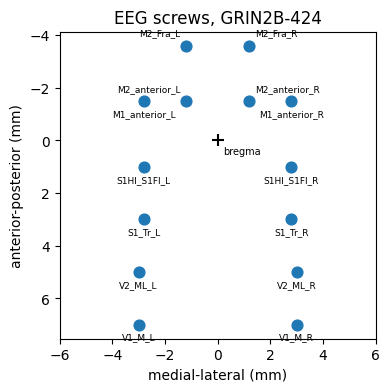

In [5]:
eeg_electrodes = electrodes[electrodes["electrode_group_name"] == "EEGArray"]
fig, ax = plt.subplots(figsize=(4, 5))
ax.scatter(eeg_electrodes["z"] / 1000, eeg_electrodes["x"] / 1000, s=60)
for row in eeg_electrodes.itertuples():
    medial = abs(row.z) < 2000  # medial screws labelled above, lateral ones below
    side = -1 if row.z < 0 else 1  # medial labels extend away from the midline
    ax.annotate(
        row.channel_name, (row.z / 1000, row.x / 1000), fontsize=6.5,
        ha=("right" if side < 0 else "left") if medial else "center",
        xytext=(4 * side if medial else 0, 7 if medial else -11), textcoords="offset points",
    )
ax.scatter([0], [0], marker="+", color="k", s=80)
ax.annotate("bregma", (0, 0), fontsize=7, xytext=(4, -10), textcoords="offset points")
ax.set_xlabel("medial-lateral (mm)")
ax.set_ylabel("anterior-posterior (mm)")
ax.invert_yaxis()
ax.set_xlim(-6, 6)
ax.set_aspect("equal")
ax.set_title(f"EEG screws, {example['subject_id']}")
plt.tight_layout()

## 2. The series

`ImportedEEG` has the sampling rate, number of samples and unit of each series, and the name of its valid-times
interval in `IntervalList`. The recordings last 72 to 100 hours; the lab scored two 24-hour baseline windows of
each, which are the rows of the file's epochs table and the `baseline_window_1` and `baseline_window_2`
intervals.

In [6]:
series = (
    pd.DataFrame(
        ImportedEEG.fetch(
            "nwb_file_name", "name", "eeg_sampling_rate", "num_samples", "unit", "interval_list_name", as_dict=True
        )
    )
    .merge(sessions[["nwb_file_name", "subject_id", "genotype"]], on="nwb_file_name")
    .assign(hours=lambda df: df["num_samples"] / df["eeg_sampling_rate"] / 3600)
)
series.pivot_table(index=["subject_id", "genotype"], columns="name", values="hours").round(1)

,name,EEGElectricalSeries,EMGElectricalSeries
subject_id,genotype,,
GRIN2B-129,Het,77.0,77.0
GRIN2B-130,Het,77.0,77.0
GRIN2B-131,Het,77.0,77.0
GRIN2B-132,WT,77.1,77.1
GRIN2B-137,Het,73.5,73.5
GRIN2B-138,Het,73.5,73.5
GRIN2B-139,Het,73.5,73.5
GRIN2B-140,WT,73.5,73.5
GRIN2B-227,Het,99.5,99.5


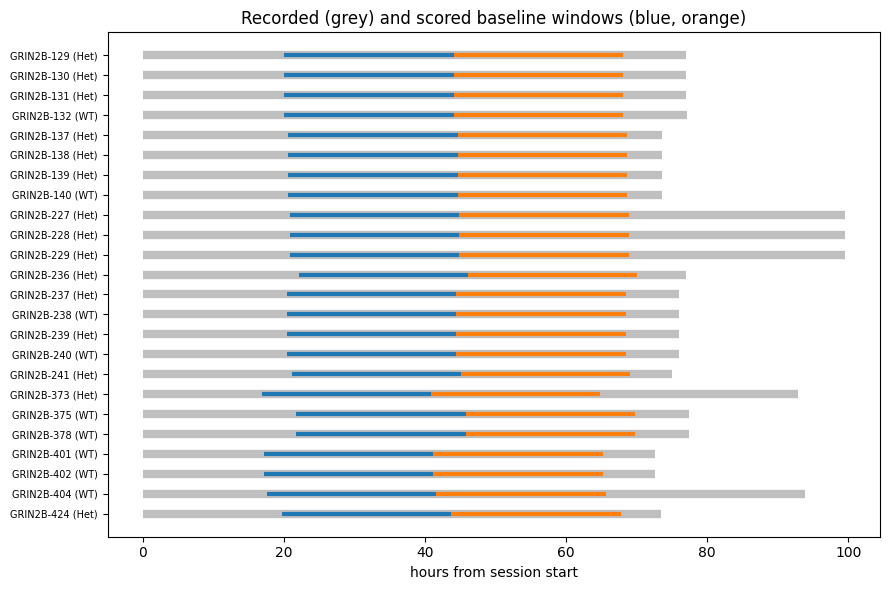

In [7]:
def interval_hours(key, interval_name):
    valid_times = (IntervalList & key & {"interval_list_name": interval_name}).fetch1("valid_times")
    return [(start / 3600, stop / 3600) for start, stop in valid_times]


fig, ax = plt.subplots(figsize=(9, 6))
for i, row in sessions.iterrows():
    key = {"nwb_file_name": row["nwb_file_name"]}
    for start, stop in interval_hours(key, "EEGElectricalSeries valid times"):
        ax.plot([start, stop], [i, i], color="0.75", lw=6, solid_capstyle="butt")
    for window, color in [("baseline_window_1", "tab:blue"), ("baseline_window_2", "tab:orange")]:
        for start, stop in interval_hours(key, window):
            ax.plot([start, stop], [i, i], color=color, lw=3, solid_capstyle="butt")
ax.set_yticks(range(len(sessions)))
ax.set_yticklabels(sessions["subject_id"] + " (" + sessions["genotype"] + ")", fontsize=7)
ax.set_xlabel("hours from session start")
ax.set_title("Recorded (grey) and scored baseline windows (blue, orange)")
ax.invert_yaxis()
plt.tight_layout()

## 3. Reading the traces

`ImportedEEG.nwb_object()` returns the `ElectricalSeries` from the NWB file. The series are rate-based, so a time
converts to a sample index with the starting time and the rate. The data are read lazily: only the slice that is
indexed is loaded.

`ImportedEEG.Electrode` maps each column of the series (`region_index`) to its electrode, which gives the channel
names for the plot. The [sleep and seizures notebook](spyglass_sleep_seizures_tutorial.ipynb) uses the same
function to plot the EEG around the lab's scored seizures.

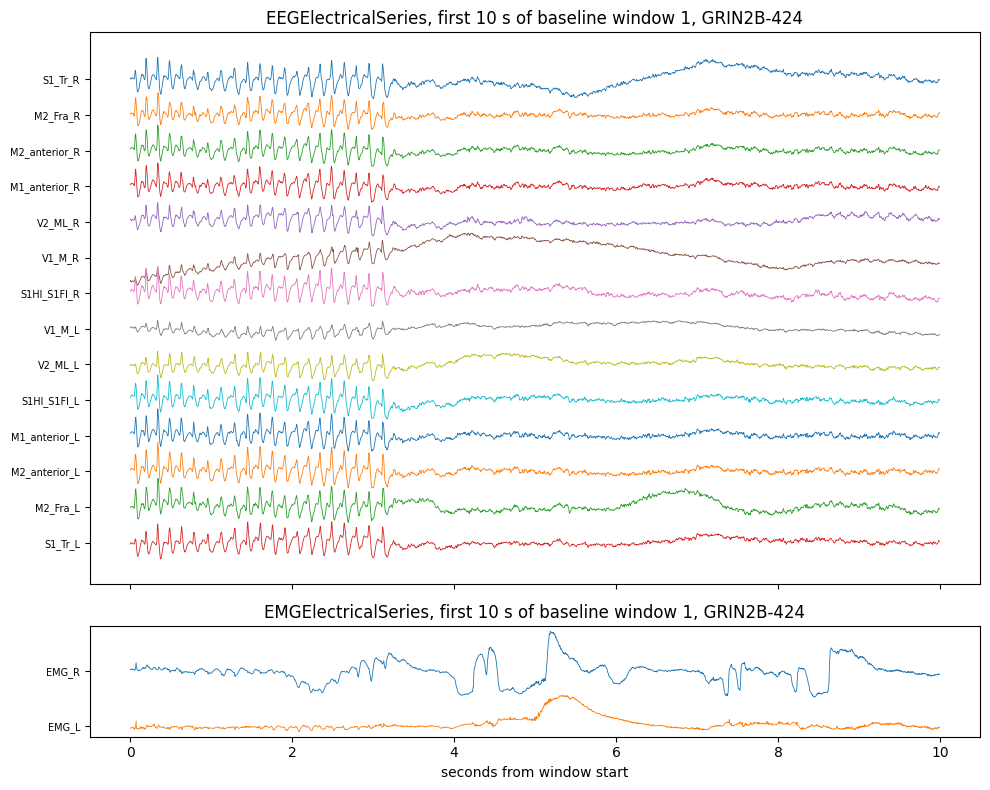

In [8]:
def load_segment(key, series_name, start, duration):
    """Times (s) and samples of a series between start and start + duration."""
    eeg_object_id = (ImportedEEG & key & {"name": series_name}).fetch1("eeg_object_id")
    es = ImportedEEG().nwb_object({**key, "eeg_object_id": eeg_object_id})
    first = int(round((start - es.starting_time) * es.rate))
    n = int(round(duration * es.rate))
    data = np.asarray(es.data[first : first + n]) * es.conversion
    times = es.starting_time + (first + np.arange(len(data))) / es.rate
    columns = (
        (ImportedEEG.Electrode & key & {"eeg_object_id": eeg_object_id})
        .fetch(format="frame")
        .reset_index()
        .sort_values("region_index")["electrode_id"]
    )
    return times, data, list(columns)


window_start = interval_hours(example_key, "baseline_window_1")[0][0] * 3600
channel_names = electrodes.set_index("electrode_id")["channel_name"]

fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=True, gridspec_kw={"height_ratios": [5, 1]})
for ax, series_name in zip(axes, ["EEGElectricalSeries", "EMGElectricalSeries"]):
    times, data, electrode_ids = load_segment(example_key, series_name, window_start, 10.0)
    data = data - np.median(data, axis=0)  # remove each channel's offset before stacking
    spacing = 6 * np.std(data)
    for column, electrode_id in enumerate(electrode_ids):
        ax.plot(times - window_start, data[:, column] - column * spacing, lw=0.6)
    ax.set_yticks([-column * spacing for column in range(len(electrode_ids))])
    ax.set_yticklabels([channel_names[e] for e in electrode_ids], fontsize=7)
    ax.set_title(f"{series_name}, first 10 s of baseline window 1, {example['subject_id']}")
axes[-1].set_xlabel("seconds from window start")
plt.tight_layout()

## 4. Data integrity

The first 1000 samples of every series, read through Spyglass, are compared with the same samples read directly
from the source NWB file in Spyglass's `raw` folder. Spyglass reads a copy of each file (with `_` added to the name)
that links to the source's data, so they should be identical.

In [9]:
N_CHECK = 1000
results = []
for name in sessions["nwb_file_name"]:
    key = {"nwb_file_name": name}
    source_path = Path(raw_dir) / name.replace("_.nwb", ".nwb")
    with NWBHDF5IO(str(source_path), "r") as io:
        source = io.read()
        for row in (ImportedEEG & key).fetch(as_dict=True):
            spyglass_series = ImportedEEG().nwb_object({**key, "eeg_object_id": row["eeg_object_id"]})
            equal = np.array_equal(
                np.asarray(spyglass_series.data[:N_CHECK]), np.asarray(source.acquisition[row["name"]].data[:N_CHECK])
            )
            results.append((name, row["name"], equal))

results = pd.DataFrame(results, columns=["nwb_file_name", "series", "equal"])
assert results["equal"].all(), results[~results["equal"]]
print(f"{results['equal'].sum()}/{len(results)} series identical to the source files.")

48/48 series identical to the source files.


## Summary

- The 24 sessions each have an `EEGArray` (14 skull screws over the cortex) and an `EMGArray` (2 neck EMG
  electrodes) in `ElectrodeGroup` and `Electrode`, and the two series in `ImportedEEG`, with a `.Electrode` row per
  channel.
- `ImportedEEG` keeps the series in the NWB file; `nwb_object()` reads any slice of it, and the read-back matches
  the source files.
- Spyglass's `Electrode` stores the group's region; the cortical area and channel name of each screw stay in the
  NWB file's electrodes table.
- The sleep scoring and seizures of the same sessions are in the
  [sleep and seizures notebook](spyglass_sleep_seizures_tutorial.ipynb).